In [1]:
# sklearn for modeling, shap for interpretability, pickle to save artifacts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import pickle

from sklearn.model_selection import (
    train_test_split, 
    cross_val_score, 
    StratifiedKFold,
    GridSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve, 
    average_precision_score,
    f1_score, 
    recall_score, 
    precision_score
)

from sklearn.calibration import CalibrationDisplay
from sklearn.preprocessing import StandardScaler
from pathlib import Path

scaler = StandardScaler()

In [2]:
DATA_DIR = Path('..') / 'data'

df = pd.read_csv(DATA_DIR / 'processed' / 'churn_clean.csv')

In [3]:
df = df.drop('customerID', axis=1)

In [4]:
# Convert target to binary so sklearn metrics work correctly (No=0, Yes=1)

df['Churn'] = df['Churn'].map({'No':0, 'Yes':1})

In [5]:
df.select_dtypes(include=['object', 'string']).columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'tenure_group'],
      dtype='str')

In [6]:
x = df.drop('Churn', axis=1)
y = df['Churn']

In [7]:
# stratify=y keeps the churn ratio (~26%) consistent across both splits

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
# CLV feature engineering. Fitted on training data only to prevent leakage
def add_clv(df_subset, medians):
    df_subset = df_subset.copy()
    df_subset['expected_lifespan'] = df_subset['Contract'].map(medians)
    # Blends contract expectation with a 30% tenure factor, clipped to 6–72 months
    df_subset['remaining_lifetime'] = (
        (df_subset['expected_lifespan'] - df_subset['tenure']).clip(lower=0)
        + df_subset['tenure'] * 0.3
    ).clip(lower=6, upper=72)
    df_subset['CLV'] = df_subset['MonthlyCharges'] * df_subset['remaining_lifetime']
    return df_subset.drop(['expected_lifespan', 'remaining_lifetime'], axis=1)

# Medians from train only. Same values applied to test to avoid leakage
contract_medians = {
    'Month-to-month': x_train[x_train['Contract'] == 'Month-to-month']['tenure'].median(),
    'One year':       x_train[x_train['Contract'] == 'One year']['tenure'].median(),
    'Two year':       x_train[x_train['Contract'] == 'Two year']['tenure'].median()
}

x_train = add_clv(x_train, contract_medians)
x_test  = add_clv(x_test,  contract_medians)

print("CLV added. Shapes:", x_train.shape, x_test.shape)

CLV added. Shapes: (5625, 21) (1407, 21)


In [9]:
# drop_first=True avoids the dummy variable trap
x_train = pd.get_dummies(x_train, drop_first=True)
x_test = pd.get_dummies(x_test, drop_first=True)

In [10]:
# fill_value=0 handles any category that only appeared in one split

x_train, x_test = x_train.align(x_test, join='left', axis=1, fill_value=0)

In [11]:
print(x_train.shape)
print(x_test.shape)

(5625, 35)
(1407, 35)


In [12]:
# fit on train, transform on test.

numeric_cols = [c for c in ['tenure', 'MonthlyCharges', 'TotalCharges', 'CLV']
                if c in x_train.columns]

x_train[numeric_cols] = scaler.fit_transform(x_train[numeric_cols])
x_test[numeric_cols]  = scaler.transform(x_test[numeric_cols])

print("Scaled columns:", numeric_cols)
print("x_train sample:\n", x_train[numeric_cols].describe().round(2))

Scaled columns: ['tenure', 'MonthlyCharges', 'TotalCharges', 'CLV']
x_train sample:
         tenure  MonthlyCharges  TotalCharges      CLV
count  5625.00         5625.00       5625.00  5625.00
mean     -0.00            0.00          0.00     0.00
std       1.00            1.00          1.00     1.00
min      -1.29           -1.55         -1.00    -1.25
25%      -0.96           -0.97         -0.83    -0.73
50%      -0.15            0.19         -0.39    -0.33
75%       0.96            0.83          0.66     0.63
max       1.61            1.78          2.81     5.73


## Model Selection

Before committing to one model, we run a quick cross-validation comparison 
to justify our choice rather than picking arbitrarily.

In [13]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

candidates = [
    ('Logistic Regression',  LogisticRegression(max_iter=1000, class_weight='balanced')),
    ('Random Forest',        RandomForestClassifier(n_estimators=100, random_state=42)),
    ('Gradient Boost',       GradientBoostingClassifier(n_estimators=100, random_state=42)),
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
selection_results = []

for name, clf in candidates:
    auc  = cross_val_score(clf, x_train, y_train, cv=cv, scoring='roc_auc',  n_jobs=-1)
    rec  = cross_val_score(clf, x_train, y_train, cv=cv, scoring='recall',   n_jobs=-1)
    
    selection_results.append({
        'Model':       name,
        'ROC-AUC':     round(auc.mean(), 4),
        'AUC Std':     round(auc.std(),  4),
        'Recall':      round(rec.mean(), 4),
        'Recall Std':  round(rec.std(),  4),
    })

selection_df = pd.DataFrame(selection_results).sort_values('ROC-AUC', ascending=False)
print(selection_df.to_string(index=False))

              Model  ROC-AUC  AUC Std  Recall  Recall Std
     Gradient Boost   0.8469   0.0041  0.5171      0.0331
Logistic Regression   0.8464   0.0063  0.8000      0.0188
      Random Forest   0.8299   0.0106  0.4856      0.0437


**Model selected: Logistic Regression (balanced)**
    
The result make the choice clear. While Gradient Boost edges out
a marginally higher AUC (0.8469 vs 0.8464, a difference of 0.0005),
Logistic Regression catches 80% of actual churners compared to only 52%
for Gradient Boost. In a retention campaign, missing a churner costs 
300 usd in lost revenue;
a false alarm costs ~ $10 in wasted outreach.
At this cost ration, recal matters far more than marginal AUC gains.

Three reasons LR is the right choice here:

1. **Recal**: 0.80 vs 0.52 for Gradient Boost. Catches significantly more at risk customers, which is primary business objective.
2. **Interpretability**: Coefficient directly show which features drive churn risk, which is valuable for business stakeholders.
3. **Probability calibration**: LR produces well-calibrated probabilities, which our CLV priority scoring depends on for reliable financial estimates.

# Building First Model

## Logistic Regression

In [34]:
# Baseline, just to see where we start
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

LogisticRegression(max_iter=1000)

In [15]:
# Grid search over C with class_weight='balanced' to handle the churn minority class
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight='balanced'),
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1
)
grid.fit(x_train, y_train)

print(f"Best C: {grid.best_params_['C']}")
print(f"Best CV AUC: {grid.best_score_:.4f}")

model_balanced = grid.best_estimator_

Best C: 100
Best CV AUC: 0.8466


In [16]:
# Unbalanced model baseline, expected to miss a lot of churners

y_pred = model.predict(x_test)

In [17]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[922 111]
 [178 196]]
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.64      0.52      0.58       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.79      0.79      1407



### ROC-AUC

In [18]:
y_prob = model.predict_proba(x_test)[:,1]
roc_auc_score(y_test, y_prob)

0.8352819522599146

       Threshold Tuning (0.3 Example)

In [19]:
y_pred_03 = (y_prob > 0.3).astype(int)

In [20]:
print(confusion_matrix(y_test, y_pred_03))
print(classification_report(y_test, y_pred_03))

[[761 272]
 [ 88 286]]
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1033
           1       0.51      0.76      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.79      0.74      0.76      1407



### Fix Class Imbalance

#### Balanced Logistic Regression

=== Model Comparison ===
                         Model  ROC-AUC  Recall  Precision     F1
           Logistic Regression   0.8353  0.5241     0.6384 0.5756
Logistic Regression (balanced)   0.8340  0.7995     0.4918 0.6090


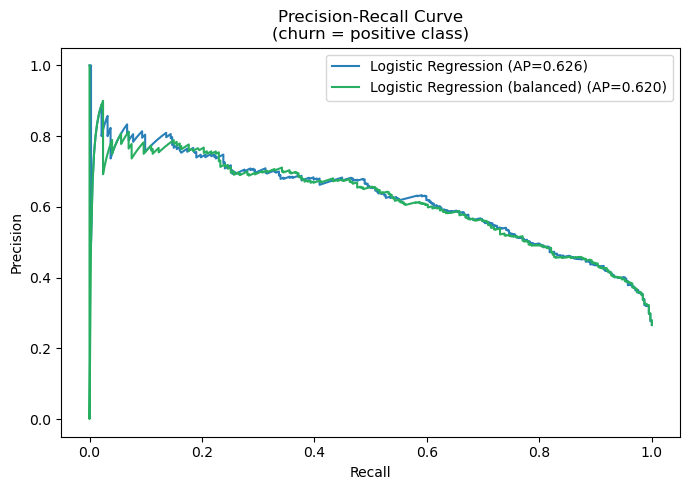


Selected model: Logistic Regression (balanced)
Reason: higher recall, better suited for imbalanced churn detection.


In [21]:
# Probabilities from both models
y_prob_lr      = model.predict_proba(x_test)[:, 1]
y_prob_lr_bal  = model_balanced.predict_proba(x_test)[:, 1]

# Predictions at default 0.5 threshold
y_pred_lr      = model.predict(x_test)
y_pred_lr_bal  = model_balanced.predict(x_test)

# Comparison table
comparison = pd.DataFrame({
    'Model':     ['Logistic Regression', 'Logistic Regression (balanced)'],
    'ROC-AUC':   [roc_auc_score(y_test, y_prob_lr),
                  roc_auc_score(y_test, y_prob_lr_bal)],
    'Recall':    [recall_score(y_test, y_pred_lr),
                  recall_score(y_test, y_pred_lr_bal)],
    'Precision': [precision_score(y_test, y_pred_lr),
                  precision_score(y_test, y_pred_lr_bal)],
    'F1':        [f1_score(y_test, y_pred_lr),
                  f1_score(y_test, y_pred_lr_bal)]
}).round(4)

print("=== Model Comparison ===")
print(comparison.to_string(index=False))

# Precision-Recall curves
fig, ax = plt.subplots(figsize=(7, 5))
for y_prob, label, color in [
    (y_prob_lr,     'Logistic Regression',            '#2980b9'),
    (y_prob_lr_bal, 'Logistic Regression (balanced)', '#27ae60')
]:
    p, r, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    ax.plot(r, p, label=f'{label} (AP={ap:.3f})', color=color)

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve\n(churn = positive class)')
ax.legend()
plt.tight_layout()
plt.show()

print("\nSelected model: Logistic Regression (balanced)")
print("Reason: higher recall, better suited for imbalanced churn detection.")

## SHAP Values

In [22]:
x_train = x_train.astype(float)
x_test = x_test.astype(float)

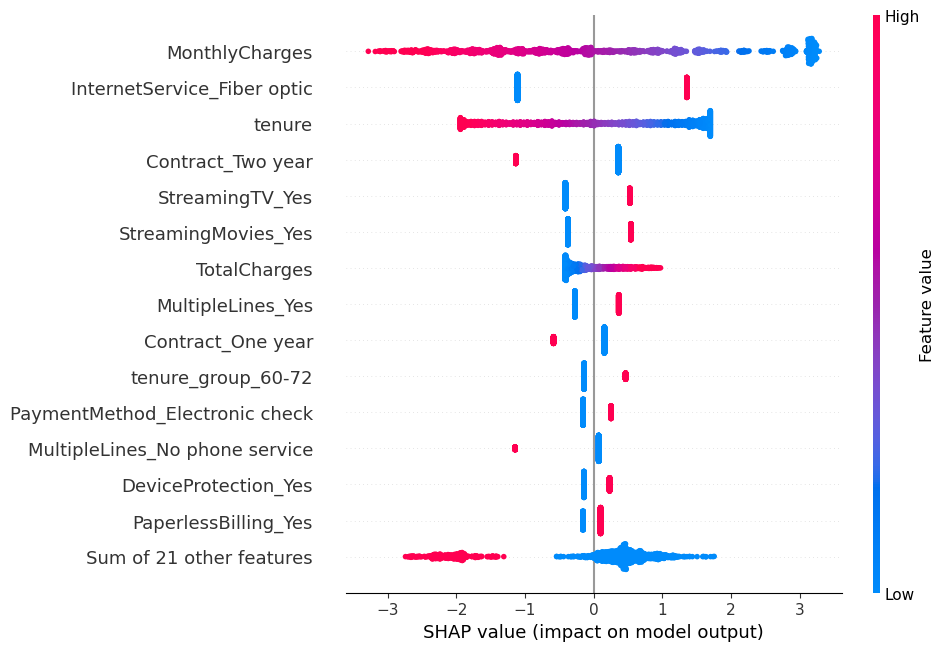

In [23]:
# LinearExplainer is exact for linear models. Each value shows how much
# a feature pushed the prediction away from the baseline.
explainer = shap.LinearExplainer(model_balanced, x_train)
shap_values = explainer.shap_values(x_test)

shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=explainer.expected_value,
    data=x_test.values,
    feature_names=x_test.columns.tolist()
)

shap.plots.beeswarm(shap_explanation, max_display=15, show=True)

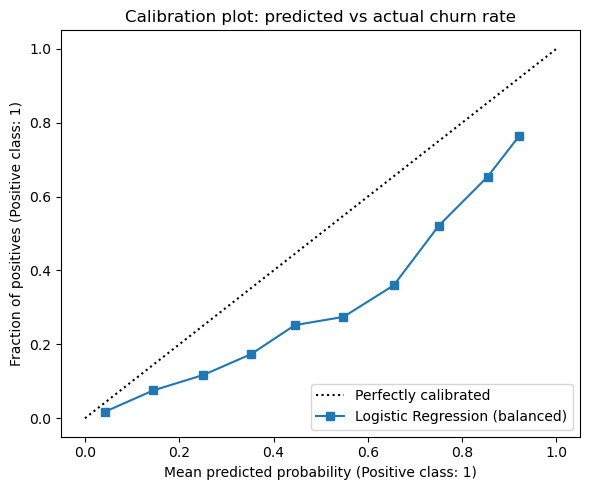

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(
    y_test, y_prob_lr_bal,
    n_bins=10,
    ax=ax,
    name='Logistic Regression (balanced)'
)
ax.set_title('Calibration plot: predicted vs actual churn rate')
plt.tight_layout()
plt.show()

**Note on probability calibration with class_weight='balanced':**
Balancing class weights adjusts the decision boundary but can shift predicted 
probabilities upward. The calibration plot above checks whether probabilities 
remain reliable. If points deviate significantly from the diagonal, applying 
`CalibratedClassifierCV(cv='prefit')` would correct them before using 
probabilities in financial calculations like expected revenue at risk.

Points near the diagonal is well-calibrated probabilities. A predicted 0.7 should mean ~70% of those customers churn.

=== Top 10 features by churn impact ===
                       feature  coefficient
   InternetService_Fiber optic     2.465907
                MonthlyCharges    -1.967241
             Contract_Two year    -1.493252
                        tenure    -1.257746
MultipleLines_No phone service    -1.217414
               StreamingTV_Yes     0.939116
           StreamingMovies_Yes     0.916512
             Contract_One year    -0.741247
             MultipleLines_Yes     0.639647
            tenure_group_60-72     0.603079


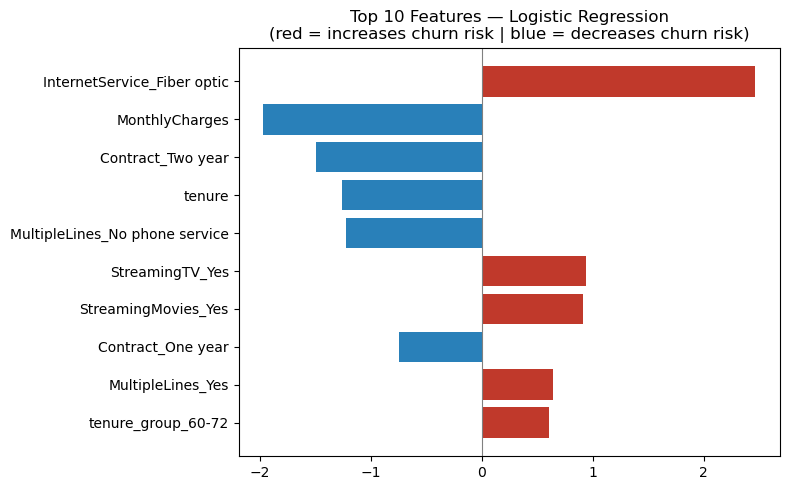

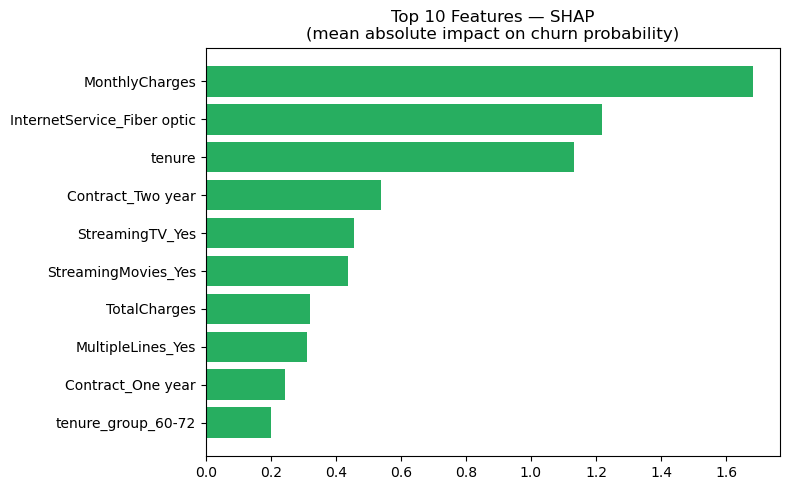


=== Where both methods agree (top 5) ===
{'InternetService_Fiber optic', 'MonthlyCharges', 'Contract_Two year', 'tenure'}


In [25]:
# Coefficients are comparable because features were StandardScaled
lr_importance = pd.DataFrame({
    'feature':     x_train.columns,
    'coefficient': model_balanced.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print("=== Top 10 features by churn impact ===")
print(lr_importance.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
top10 = lr_importance.head(10)
colors = ['#c0392b' if v > 0 else '#2980b9' for v in top10['coefficient']]
ax.barh(top10['feature'], top10['coefficient'], color=colors)
ax.axvline(0, color='gray', linewidth=0.8)
ax.set_title('Top 10 Features — Logistic Regression\n(red = increases churn risk | blue = decreases churn risk)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# SHAP: mean absolute value per feature
shap_mean = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=x_train.columns
).sort_values(ascending=True).tail(10)

fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.barh(shap_mean.index, shap_mean.values, color='#27ae60')
ax2.set_title('Top 10 Features — SHAP\n(mean absolute impact on churn probability)')
plt.tight_layout()
plt.show()

# Features both methods agree on are the most trustworthy signals
print("\n=== Where both methods agree (top 5) ===")
lr_top = set(lr_importance.head(5)['feature'])
shap_top = set(shap_mean.tail(5).index)
agreed = lr_top & shap_top
print(agreed if agreed else "Check top 10 for overlaps")

# Treshold Tuning

In [26]:
# Sweep thresholds and find which minimizes total business cost
# FN (missed churner) costs 30x more than FP (unnecessary retention offer)
y_prob = model_balanced.predict_proba(x_test)[:,1]
thresholds = np.arange(0.1, 0.9, 0.05)
results = []

for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    
    # Cost assumptions can be adjusted based on business reality:
    # FN_COST = $300: estimated revenue lost per churner not caught
    # FP_COST = $10:  estimated cost of retention offer sent to loyal customer
    FN_COST = 300
    FP_COST = 10
    cost = (fn * FN_COST) + (fp * FP_COST)
    results.append([t, fn, fp, cost])
    
df_results = pd.DataFrame(results, columns=['threshold', 'FN', 'FP', 'cost'])
df_results.sort_values(by='cost').head()

,threshold,FN,FP,cost
0,0.10,6,704,8840
1,0.15,11,620,9500
2,0.20,18,557,10970
3,0.25,25,518,12680
4,0.30,29,474,13440


     ROC Curve Visualization

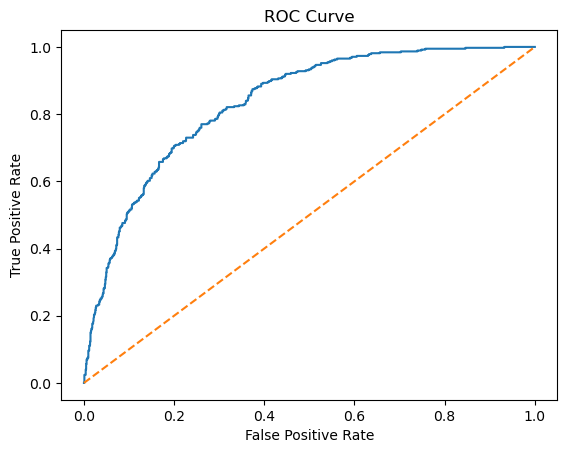

In [27]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

## CLV + Business Layer

In [28]:
# Score the full dataset, same pipeline as train/test
df_full = add_clv(df.drop('Churn', axis=1), contract_medians)

x_full = pd.get_dummies(df_full, drop_first=True)
x_full = x_full.reindex(columns=x_train.columns, fill_value=0)

df['CLV'] = df_full['CLV']
df['churn_probability'] = model_balanced.predict_proba(x_full)[:,1]

   Risk Segmentation

In [29]:
df['risk_segment'] = pd.cut(
    df['churn_probability'],
    bins=[0, 0.3, 0.6, 1],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

    Priority Score

In [30]:
CONTRACT_WEIGHTS = {
    'Month-to-month': 1.5,
    'One year':       1.0,
    'Two year':       0.7
}

def compute_priority_score(prob, clv, contract):
    """p^1.5 amplifies high-confidence predictions.
    Contract weight adjusts for churn cost by tenure type."""
    weight = CONTRACT_WEIGHTS.get(contract, 1.0)
    return (prob ** 1.5) * clv * weight

df['priority_score'] = df.apply(
    lambda r: compute_priority_score(
        r['churn_probability'], r['CLV'], r['Contract']
    ), axis=1
)

In [31]:
df.groupby('risk_segment')['CLV'].agg(['count','mean','sum'])

df.sort_values(by='priority_score', ascending=False).head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,CLV,churn_probability,risk_segment,priority_score
3814,Male,1,Yes,No,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Credit card (automatic),112.90,8061.50,0,60-72,2438.640,1.0,High Risk,3657.9600
2780,Female,0,No,No,25,Yes,Yes,Fiber optic,No,Yes,...,No,Electronic check,108.90,2809.05,0,24-48,5063.850,1.0,High Risk,3544.6950
5243,Male,1,Yes,No,71,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Electronic check,107.50,7713.55,0,60-72,2289.750,1.0,High Risk,3434.6250
565,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,...,No,Electronic check,101.90,1667.25,0,12-24,3413.650,1.0,High Risk,3413.6500
3854,Female,0,No,Yes,26,Yes,No,Fiber optic,No,Yes,...,Yes,Electronic check,105.45,2715.30,0,24-48,4829.610,1.0,High Risk,3380.7270
5693,Male,1,Yes,Yes,71,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Credit card (automatic),105.10,7548.10,1,60-72,2238.630,1.0,High Risk,3357.9450
2074,Male,0,Yes,Yes,70,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Electronic check,106.05,7554.05,0,60-72,2227.050,1.0,High Risk,3340.5750
4439,Male,0,Yes,No,68,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Electronic check,107.70,7320.90,0,60-72,2197.080,1.0,High Risk,3295.6200
4799,Female,0,No,Yes,34,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Credit card (automatic),116.15,3946.90,0,24-48,4669.230,1.0,High Risk,3268.4610
93,Female,0,No,No,65,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Credit card (automatic),111.05,7107.00,0,60-72,2165.475,1.0,High Risk,3248.2125


    Visualization

<Axes: xlabel='CLV', ylabel='churn_probability'>

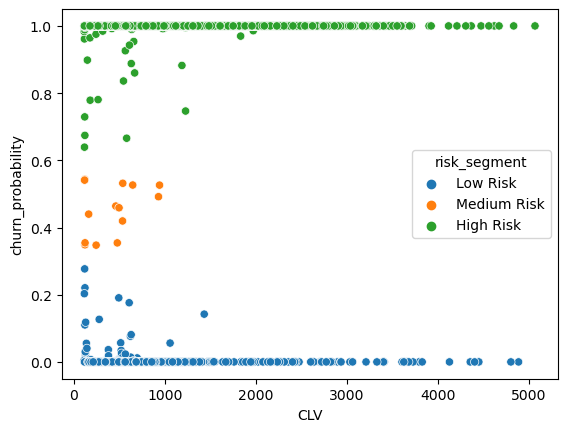

In [32]:
sns.scatterplot(
    x='CLV',
    y='churn_probability',
    hue='risk_segment',
    data=df
)

In [33]:
APP_DIR = Path('..') / 'app'

# Thresholds derived from actual score distribution, not hardcoded
high_threshold = df['priority_score'].quantile(0.75)
medium_threshold = df['priority_score'].quantile(0.40)
model = model_balanced

# Save everything needed to reproduce predictions in the app
pickle.dump(model,                      open(APP_DIR / "model.pkl", "wb"))
pickle.dump(x_train.columns.tolist(),   open(APP_DIR / "columns.pkl", "wb"))
pickle.dump(contract_medians,           open(APP_DIR / "contract_medians.pkl", "wb"))
pickle.dump(
    {'high': high_threshold, 'medium': medium_threshold},
                                        open(APP_DIR / "priority_thresholds.pkl", "wb")
)
pickle.dump(scaler,                     open(APP_DIR / "scaler.pkl", "wb"))
pickle.dump(numeric_cols,               open(APP_DIR / "numeric_cols.pkl", "wb"))

print("All models saved to app/ folder.")

All models saved to app/ folder.


## Final Business Recommendations

**Key findings:**
- Month-to-month customers with tenure < 12 months represent the highest churn risk (~48%)
- Fiber optic internet users churn at ~42%, suggesting pricing or service quality concerns
- Electronic check payment correlates with higher churn — possibly a customer satisfaction signal

**Model decisions:**
- Logistic Regression (balanced) selected for interpretability and competitive ROC-AUC
- Threshold set at 0.3 to prioritize recall — catching more churners outweighs false alarm cost
- Priority score = (p^1.5 × CLV × contract weight) surfaces highest-value at-risk customers

**Recommended actions:**
1. Target month-to-month, short-tenure customers with early loyalty incentives
2. Investigate fiber optic service satisfaction — pricing or quality intervention needed
3. Prioritize retention budget toward high-CLV customers using the priority score dashboard